# Experiment 1: Time and frequency domain, and the pendulum
**CSAI4014 · Algorithms for Intelligent Systems and Robotics**

**Aim.** To represent a sampled signal in the time domain and in the frequency domain using the discrete
Fourier transform, and to simulate the motion of a simple pendulum by numerical integration of its equation of motion.

**Objectives**
1. Generate a sampled signal of known composition; state $f_s$, record length $T$ and resolution $\Delta f$.
2. Compute an amplitude spectrum and read amplitudes in the units of the original signal.
3. Predict and then demonstrate aliasing.
4. Write a second-order ODE as a first-order system and integrate it numerically.
5. Produce a phase portrait and relate its shape to the energy of the motion.
6. Measure the dependence of a pendulum's period on its amplitude.

## Theory (summary)
* $\Delta f = f_s/N = 1/T$ (resolution depends only on record length), $f_{max} = f_s/2$ (Nyquist).
* A component above $f_s/2$ folds back and appears at $|f_s - f|$ (aliasing).
* Pendulum: $\ddot\theta + \frac{b}{m}\dot\theta + \frac{g}{L}\sin\theta = 0$, written as the state $(\theta,\omega)$.
  Small-angle period $T_0 = 2\pi\sqrt{L/g}$.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## Example 1: Building a signal and reading its spectrum

In [2]:
fs, T = 500.0, 2.0                 # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1/fs)
N = t.size                         # N = 1000 samples

rng = np.random.default_rng(0)     # seeded: the result is reproducible
x = (1.00*np.sin(2*np.pi* 5*t)
   + 0.50*np.sin(2*np.pi*20*t)
   + 0.25*np.sin(2*np.pi*50*t)
   + 0.20*rng.standard_normal(N))

X = np.fft.rfft(x)                 # real input -> one-sided spectrum
f = np.fft.rfftfreq(N, d=1/fs)     # the matching frequency axis, in Hz
amp = np.abs(X) * 2.0 / N          # amplitudes in the units of x
amp[0] /= 2.0                      # the zero-frequency term is not doubled

print('N =', N, ' resolution df =', fs/N, 'Hz', ' Nyquist =', fs/2, 'Hz')
print('peaks at:', np.round(f[amp > 0.1], 2))
print('amplitudes:', np.round(amp[amp > 0.1], 3))

N = 1000  resolution df = 0.5 Hz  Nyquist = 250.0 Hz
peaks at: [ 5. 20. 50.]
amplitudes: [1.008 0.492 0.252]


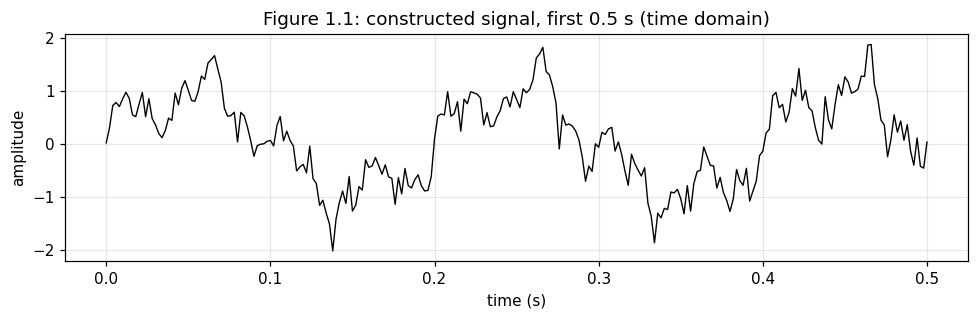

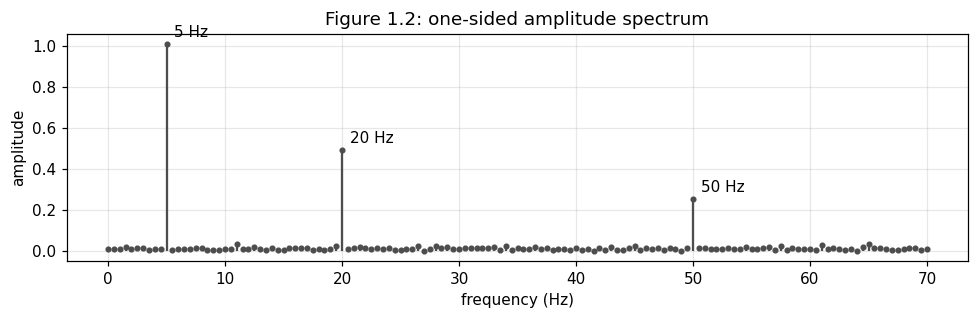

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
m = t <= 0.5
ax.plot(t[m], x[m], lw=0.9, color='k')
ax.set_xlabel('time (s)'); ax.set_ylabel('amplitude')
ax.set_title('Figure 1.1: constructed signal, first 0.5 s (time domain)')
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig1_1_time.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
sel = f <= 70
ax.stem(f[sel], amp[sel], basefmt=' ', linefmt='0.3', markerfmt='.')
for fp in (5, 20, 50):
    ax.annotate(f'{fp} Hz', (fp, amp[f == fp][0]), textcoords='offset points', xytext=(5, 5))
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('amplitude')
ax.set_title('Figure 1.2: one-sided amplitude spectrum')
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig1_2_spectrum.png'); plt.show()

**What to notice.** `rfft` (not `fft`) because the input is real; the axis comes from `rfftfreq`;
the factor $2/N$ makes peak heights equal the amplitudes.

### Spectral leakage check (T = 1.7 s)
With $T = 1.7$ s the components no longer fall exactly on transform bins, so the peaks broaden.

df = 0.5882 Hz


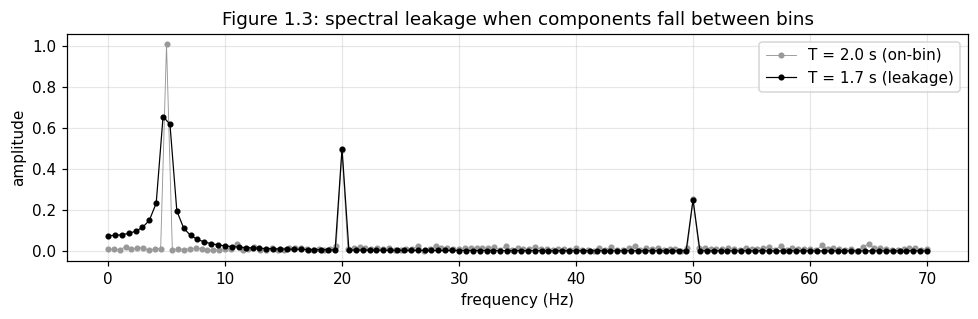

In [4]:
T2 = 1.7
t2 = np.arange(0, T2, 1/fs); N2 = t2.size
x2 = 1.00*np.sin(2*np.pi*5*t2) + 0.50*np.sin(2*np.pi*20*t2) + 0.25*np.sin(2*np.pi*50*t2)
amp2 = np.abs(np.fft.rfft(x2))*2/N2; f2 = np.fft.rfftfreq(N2, 1/fs)
print('df =', round(fs/N2, 4), 'Hz')
fig, ax = plt.subplots(figsize=(9, 3))
sel = f2 <= 70
ax.plot(f[f <= 70], amp[f <= 70], '.-', lw=0.6, color='0.6', label='T = 2.0 s (on-bin)')
ax.plot(f2[sel], amp2[sel], '.-', lw=0.8, color='k', label='T = 1.7 s (leakage)')
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('amplitude'); ax.legend()
ax.set_title('Figure 1.3: spectral leakage when components fall between bins')
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig1_3_leakage.png'); plt.show()

## Example 2: Making aliasing happen

In [5]:
fs_a = 8.0                              # deliberately below 2 x 5 Hz
t_a = np.arange(0, 1.0, 1/fs_a)
x_a = np.sin(2*np.pi*5*t_a)             # a 5 Hz sine, undersampled

X_a = np.fft.rfft(x_a)
f_a = np.fft.rfftfreq(t_a.size, d=1/fs_a)
print('Nyquist =', fs_a/2, 'Hz')
print('peak at:', f_a[np.argmax(np.abs(X_a))], 'Hz')   # 3 Hz, not 5 Hz
print('predicted alias |fs - f| =', abs(fs_a - 5), 'Hz')

Nyquist = 4.0 Hz
peak at: 3.0 Hz
predicted alias |fs - f| = 3.0 Hz


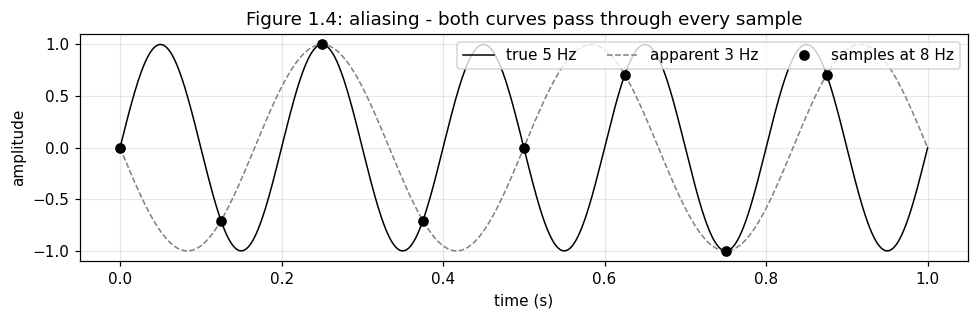

In [6]:
tc = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(tc, np.sin(2*np.pi*5*tc), 'k', lw=1, label='true 5 Hz')
ax.plot(tc, -np.sin(2*np.pi*3*tc), '--', color='0.5', lw=1, label='apparent 3 Hz')
ax.plot(t_a, x_a, 'ko', label='samples at 8 Hz')
ax.set_xlabel('time (s)'); ax.set_ylabel('amplitude'); ax.legend(loc='upper right', ncol=3)
ax.set_title('Figure 1.4: aliasing - both curves pass through every sample')
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig1_4_aliasing.png'); plt.show()

## Example 3: The pendulum, damping, and the amplitude effect

In [7]:
from scipy.integrate import solve_ivp

g, L = 9.81, 1.0

def pendulum(t, y, b):                  # NOTE the signature: (t, y), not (y, t)
    theta, omega = y
    return [omega, -b*omega - (g/L)*np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0],
                    args=(b,), t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

T0 = 2*np.pi*np.sqrt(L/g)               # small-angle prediction
print('T0 =', round(T0, 4), 's')

for a in (5, 95, 175):                  # period from the spectrum of theta(t)
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    fs2 = 1/(tt[1]-tt[0])
    A = np.abs(np.fft.rfft(th))
    fr = np.fft.rfftfreq(th.size, 1/fs2)
    pk = fr[1:][np.argmax(A[1:])]       # skip bin 0: it holds the mean
    print(f'{a:>4} deg -> period {1/pk:.3f} s   ratio to T0 = {1/pk/T0:.2f}')

T0 = 2.0061 s


   5 deg -> period 2.000 s   ratio to T0 = 1.00


  95 deg -> period 2.400 s   ratio to T0 = 1.20


 175 deg -> period 6.001 s   ratio to T0 = 2.99


### Period by zero crossings (independent of the spectrum)

In [8]:
def period_zero_crossings(t, th):
    # upward zero crossings, linearly interpolated between samples
    idx = np.where((th[:-1] < 0) & (th[1:] >= 0))[0]
    tc = t[idx] - th[idx]*(t[idx+1]-t[idx])/(th[idx+1]-th[idx])
    return np.mean(np.diff(tc))

print(f"{'angle':>6} {'zero-cross (s)':>15} {'spectrum (s)':>13} {'T0 (s)':>8}")
for a in (5, 95, 175):
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    A = np.abs(np.fft.rfft(th)); fr = np.fft.rfftfreq(th.size, tt[1]-tt[0])
    p_spec = 1/fr[1:][np.argmax(A[1:])]
    print(f'{a:>6} {period_zero_crossings(tt, th):>15.4f} {p_spec:>13.3f} {T0:>8.4f}')

 angle  zero-cross (s)  spectrum (s)   T0 (s)


     5          2.0070         2.000   2.0061


    95          2.4174         2.400   2.0061


   175          5.7728         6.001   2.0061


The zero-crossing estimate at 5° is much closer to $T_0 \approx 2.006$ s than the spectral estimate, whose
resolution is limited to $\Delta f = 1/60$ Hz. The 0.3 % gap in the spectral value is a resolution artefact, not physics.

### Damping and phase portraits

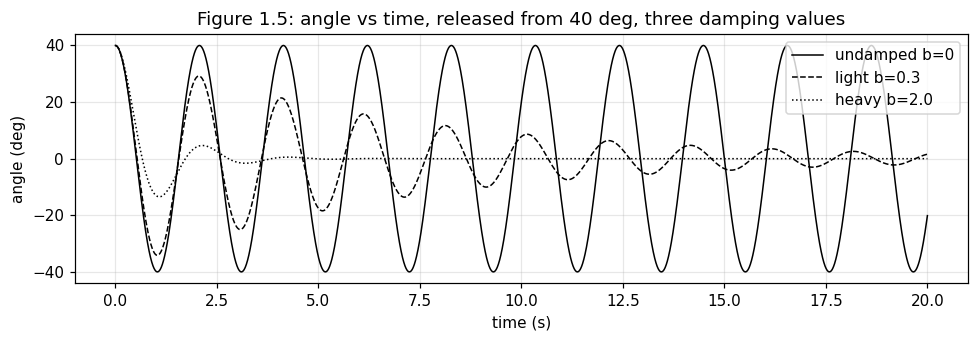

In [9]:
dampings = [(0.0, 'undamped b=0', '-'), (0.3, 'light b=0.3', '--'), (2.0, 'heavy b=2.0', ':')]
fig, ax = plt.subplots(figsize=(9, 3.2))
runs = {}
for b, lab, ls in dampings:
    tt, th, om = simulate(40, b)
    runs[b] = (th, om)
    ax.plot(tt, np.rad2deg(th), ls, color='k', lw=1, label=lab)
ax.set_xlabel('time (s)'); ax.set_ylabel('angle (deg)'); ax.legend(loc='upper right')
ax.set_title('Figure 1.5: angle vs time, released from 40 deg, three damping values')
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig1_5_damping.png'); plt.show()

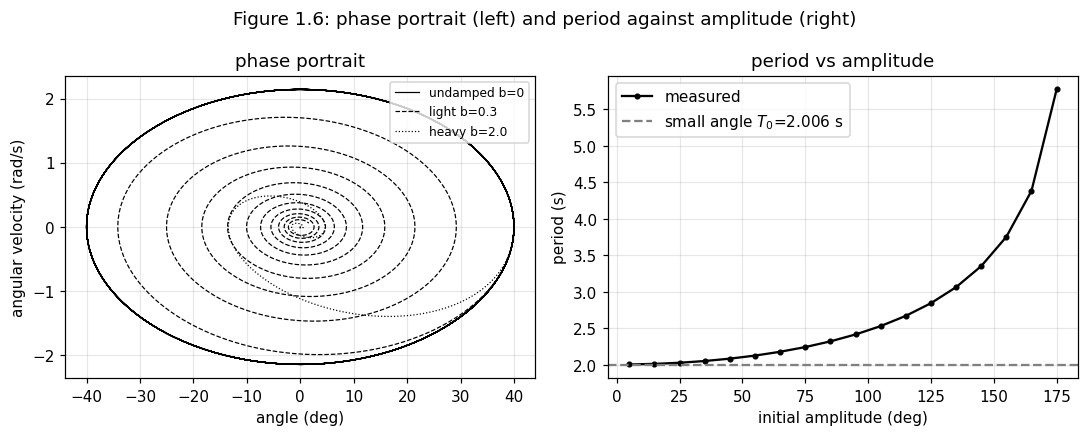

   5 deg  period 2.007 s  ratio 1.00
  15 deg  period 2.015 s  ratio 1.00
  25 deg  period 2.030 s  ratio 1.01
  35 deg  period 2.054 s  ratio 1.02
  45 deg  period 2.086 s  ratio 1.04
  55 deg  period 2.128 s  ratio 1.06
  65 deg  period 2.180 s  ratio 1.09
  75 deg  period 2.245 s  ratio 1.12
  85 deg  period 2.323 s  ratio 1.16
  95 deg  period 2.417 s  ratio 1.21
 105 deg  period 2.532 s  ratio 1.26
 115 deg  period 2.672 s  ratio 1.33
 125 deg  period 2.846 s  ratio 1.42
 135 deg  period 3.065 s  ratio 1.53
 145 deg  period 3.353 s  ratio 1.67
 155 deg  period 3.754 s  ratio 1.87
 165 deg  period 4.384 s  ratio 2.19
 175 deg  period 5.773 s  ratio 2.88


In [10]:
amps = np.arange(5, 180, 10)
periods = []
for a in amps:
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    periods.append(period_zero_crossings(tt, th))
periods = np.array(periods)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for b, lab, ls in dampings:
    th, om = runs[b]
    ax1.plot(np.rad2deg(th), om, ls, color='k', lw=0.8, label=lab)
ax1.set_xlabel('angle (deg)'); ax1.set_ylabel('angular velocity (rad/s)')
ax1.set_title('phase portrait'); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)
ax2.plot(amps, periods, 'k.-', label='measured')
ax2.axhline(T0, ls='--', color='0.5', label=f'small angle $T_0$={T0:.3f} s')
ax2.set_xlabel('initial amplitude (deg)'); ax2.set_ylabel('period (s)')
ax2.set_title('period vs amplitude'); ax2.legend(); ax2.grid(alpha=0.3)
fig.suptitle('Figure 1.6: phase portrait (left) and period against amplitude (right)')
plt.tight_layout(); plt.savefig('figs/fig1_6_phase_period.png'); plt.show()

for a, p in zip(amps, periods):
    print(f'{a:>4} deg  period {p:.3f} s  ratio {p/T0:.2f}')

## Observations to record
| Quantity | Value |
|---|---|
| $f_s$ | 500 Hz |
| $T$ | 2 s |
| $N$ | 1000 |
| $\Delta f$ | 0.5 Hz |
| $f_s/2$ | 250 Hz |
| Measured peaks | 5, 20, 50 Hz with amplitudes ≈ 1.00, 0.50, 0.25 |
| Aliased peak (5 Hz at $f_s$ = 8 Hz) | 3 Hz |
| $T_0$ | 2.006 s (g = 9.81, L = 1 m) |
| Damping coefficients used | 0, 0.3, 2.0 |

The period values from zero crossings and from the spectrum are printed above.

## Discussion
* **Expected:** peaks at 5, 20 and 50 Hz with the set amplitudes; a 5 Hz tone sampled at 8 Hz appearing at 3 Hz; a pendulum period near $T_0$ for small angles that grows with amplitude.
* **Observed:** all three happened. The undamped phase orbit is closed (energy conserved), and the damped orbits spiral into the origin.
  The period rises from ≈2.01 s at 5° to ≈6 s at 175°.
* **Differences:** the spectral period at 5° (2.000 s against 2.006 s) is limited by the $1/60$ Hz resolution of a 60 s record. Zero crossings remove this artefact.

## Viva questions (short answers)
1. **5 Hz vs aliased 45 Hz?** At $f_s$ = 500 Hz, 45 Hz is below Nyquist and would appear at 45 Hz. Only a component near $f_s \pm 5$ Hz could fold to 5 Hz. You can only be sure if an anti-alias filter was applied before sampling.
2. **Resolution?** $\Delta f = 1/T$, set by the record length. Sampling faster raises $N$ and $f_s$ together, so their ratio does not change.
3. **(t, y)?** `solve_ivp` calls `fun(t, y)`. With the arguments swapped the state would be read as time, giving silently wrong results.
4. **Area of a closed orbit?** It is proportional to the energy of the motion (the action). Larger orbits mean more energy.
5. **Divergence near 180°?** The inverted position is an unstable equilibrium. The bob slows toward it and spends ever longer near the top, so the period tends to infinity.